# Практическая работа № 5. Линейная регрессия

Цель: построить модель зависимости медианной стоимости домов `MEDV` от признака `LSTAT`, вычислить её параметры методом наименьших квадратов и визуализировать результат.

Это задача обучения **с учителем**: в данных известны правильные ответы (`MEDV`).

Окружение: **Python 3.11 (ml05)**. Файл `housing.csv` должен находиться рядом с ноутбуком. Выполните ячейки сверху вниз через **Run All**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

%matplotlib inline
plt.style.use('seaborn-v0_8')

Matplotlib is building the font cache; this may take a moment.


In [2]:
from pathlib import Path

output_dir = Path('results')
output_dir.mkdir(exist_ok=True)

In [3]:
column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS',
                'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
boston_data = pd.read_csv('housing.csv', header=None, sep=r'\s+', names=column_names)
boston_data.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [4]:
boston_data.info()
print(f'Число объектов: {len(boston_data)}')
print(f'Пропущенных значений: {boston_data.isna().sum().sum()}')

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB
Число объектов: 506
Пропущенных значений: 0


## Данные

| Признак | Описание |
|---|---|
| CRIM | Уровень преступности на душу населения |
| ZN | Доля земли под жилую застройку с участками более 25 000 кв. футов |
| INDUS | Доля земли, занятой предприятиями вне розничной торговли |
| CHAS | Прилегание участка к реке Чарльз: 1 - да, 0 - нет |
| NOX | Концентрация оксидов азота |
| RM | Среднее число комнат |
| AGE | Доля жилья, построенного до 1940 года |
| DIS | Взвешенное расстояние до пяти центров занятости |
| RAD | Индекс доступности радиальных автодорог |
| TAX | Ставка налога на имущество |
| PTRATIO | Соотношение учеников и учителей |
| B | Исторический показатель состава населения: 1000 × (Bk − 0.63)² |
| LSTAT | Процент населения с низким социальным статусом |
| MEDV | Медианная стоимость домов, тыс. долларов; целевой признак |

## Выбор признака

Проверяем отсутствие пропусков и числовые типы данных. Вычисляем корреляции признаков с `MEDV` и сравниваем их абсолютные значения. Знак самой корреляции показывает направление связи.

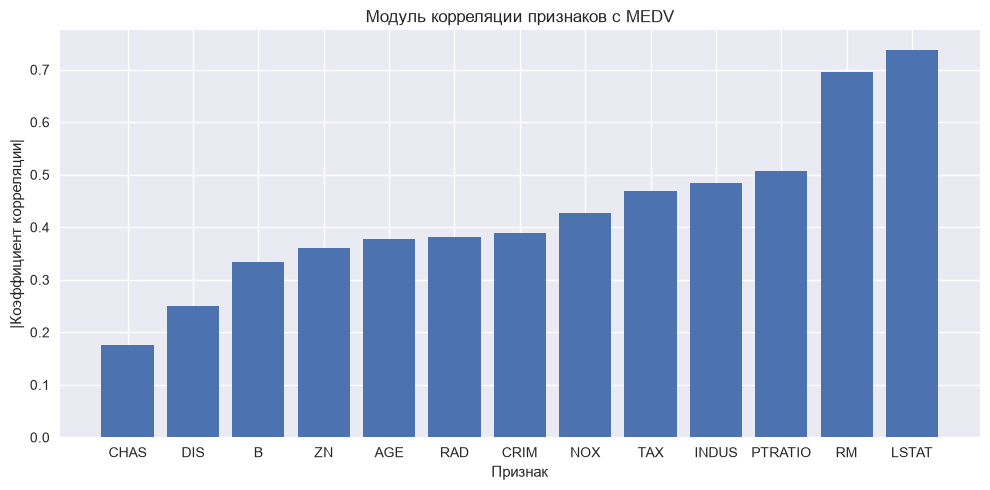

Наиболее связанный признак: LSTAT
Корреляция LSTAT и MEDV: -0.7377


In [5]:
corr_with_target = boston_data.corr()['MEDV'].drop('MEDV')
abs_corr = corr_with_target.abs().sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(abs_corr.index, abs_corr.values)
ax.set_title('Модуль корреляции признаков с MEDV')
ax.set_xlabel('Признак')
ax.set_ylabel('|Коэффициент корреляции|')
fig.tight_layout()
fig.savefig(output_dir / 'correlations.png', dpi=160)
plt.show()
print(f'Наиболее связанный признак: {abs_corr.idxmax()}')
print(f"Корреляция LSTAT и MEDV: {corr_with_target['LSTAT']:.4f}")

## Матрица наблюдений и правильные ответы

Наибольшую корреляцию по модулю имеет `LSTAT`; связь с `MEDV` отрицательная. Выбираем `X` как таблицу из одного столбца `LSTAT`, а `y` как вектор цен `MEDV`.

Модель: $\hat y = w_0 + w_1 x$.

In [6]:
X = boston_data[['LSTAT']]  # Двойные скобки сохраняют двумерную таблицу.
X.head()

,LSTAT
0,4.98
1,9.14
2,4.03
3,2.94
4,5.33


In [7]:
y = boston_data['MEDV']
y.head()

0    24.0
1    21.6
2    34.7
3    33.4
4    36.2
Name: MEDV, dtype: float64

## Метод наименьших квадратов

Добавляем к `X` столбец единиц для свободного члена. Затем вычисляем коэффициенты аналитически:

$$w = (X^T X)^{-1} X^T y.$$

В NumPy оператор `@` выполняет матричное умножение, `.T` - транспонирование, `np.linalg.inv` - обращение матрицы. Для выбранного признака матрица обратима.

In [8]:
def linear_regression(X, y):
    # Столбец единиц позволяет вычислить свободный член w0.
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    X_with_bias = np.column_stack([np.ones(X.shape[0]), X])
    Q = np.linalg.inv(X_with_bias.T @ X_with_bias)
    return Q @ X_with_bias.T @ y

In [9]:
w = linear_regression(X, y)
print(f'Вектор коэффициентов: {w}')
print(f'w0: {w[0]:.2f}')
print(f'w1: {w[1]:.2f}')
print(f'MEDV = {w[0]:.2f} {w[1]:+.2f} × LSTAT')

Вектор коэффициентов: [34.55384088 -0.95004935]
w0: 34.55
w1: -0.95
MEDV = 34.55 -0.95 × LSTAT


## Интерпретация и предсказание

Получается модель **MEDV ≈ 34.55 − 0.95 × LSTAT**.

- `w0 ≈ 34.55` - значение модели при `LSTAT = 0`; это экстраполяция за пределы наблюдаемого диапазона.
- `w1 ≈ −0.95` - при увеличении `LSTAT` на один процентный пункт предсказанная стоимость уменьшается примерно на 0.95 тыс. долларов.

Подставим `LSTAT = 5.18`. Коэффициенты описывают статистическую связь, а не доказывают причинное влияние.

In [10]:
x_example = 5.18
y_example = w[0] + w[1] * x_example
print(f'LSTAT: {x_example}%')
print(f'Предсказанная стоимость: {y_example:.2f} тыс. долларов')

LSTAT: 5.18%
Предсказанная стоимость: 29.63 тыс. долларов


## Визуализация

Отображаем наблюдения точками, а предсказания модели - прямой. Перед построением линии сортируем значения `LSTAT`.

In [11]:
def plot_regression_2d(X, y_true, y_pred, xlabel='LSTAT (%)', ylabel='MEDV (тыс. долларов)'):
    x_values = np.asarray(X).ravel()
    order = np.argsort(x_values)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(x_values, y_true, alpha=0.65, label='Исходные данные')
    ax.plot(x_values[order], np.asarray(y_pred).ravel()[order],
            color='black', linewidth=2, label='Линейная регрессия')
    ax.set_title('Зависимость стоимости домов от LSTAT')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend()
    fig.tight_layout()
    return fig

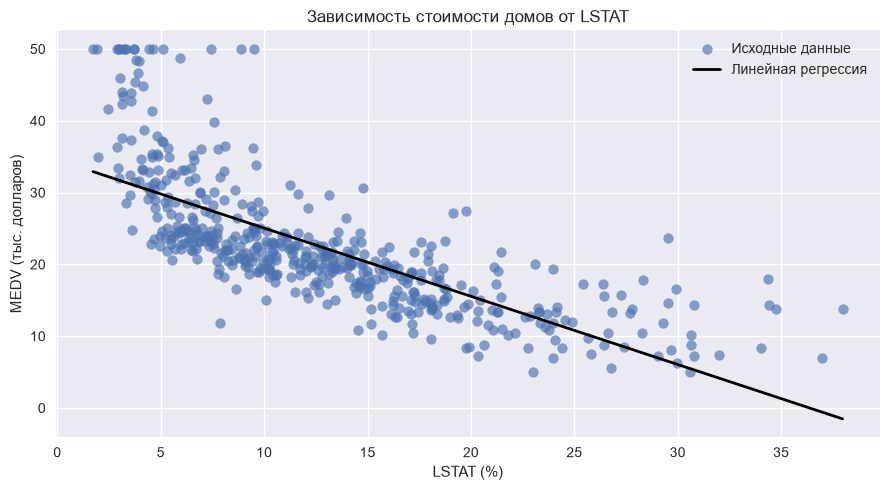

In [12]:
y_predict = w[0] + w[1] * X['LSTAT'].to_numpy()
fig = plot_regression_2d(X, y, y_predict)
fig.savefig(output_dir / 'regression.png', dpi=160)
plt.show()

## Проверка вычислений

Сравним ручной расчёт с `LinearRegression` из scikit-learn на тех же данных.

In [13]:
model = LinearRegression().fit(X, y)
w_sklearn = np.r_[model.intercept_, model.coef_]
print(f'NumPy:        {w}')
print(f'scikit-learn: {w_sklearn}')
print(f'Коэффициенты совпадают: {np.allclose(w, w_sklearn)}')

NumPy:        [34.55384088 -0.95004935]
scikit-learn: [34.55384088 -0.95004935]
Коэффициенты совпадают: True


## Вывод

Данные содержат 506 наблюдений и 14 числовых столбцов, пропусков нет. Наиболее связанный с ценой признак - `LSTAT` (корреляция около −0.738).

Методом наименьших квадратов получены коэффициенты `w0 ≈ 34.55`, `w1 ≈ −0.95`. При `LSTAT = 5.18` прогноз составляет **29.63 тыс. долларов**. Ручное вычисление согласуется со scikit-learn.

Разброс точек относительно прямой показывает, что один признак не объясняет всю изменчивость цен. Проверка совпадения коэффициентов подтверждает расчёт; качество прогноза на новых данных в этой работе отдельно не оценивалось.